In [1]:
import os
import math
import glob
import copy
from typing import Any, Dict, List, Optional

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import pytorch_lightning as pl
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split

import monai
from monai.data import Dataset, CacheDataset
from monai.transforms import (
    Compose,
    LoadImaged,
    EnsureChannelFirstd,
    Orientationd,
    Resized,
    RandRotated,
    RandFlipd,
    RandScaleIntensityd,
    EnsureTyped,
    Transform,
    NormalizeIntensityd,
    RandZoomd,
    RandShiftIntensityd,
    RandAdjustContrastd,
    RandRotate90d,
    CenterSpatialCropd

)
from monai.networks.nets.resnet import ResNet, resnet18, resnet50, resnet101
from pytorch_lightning.callbacks import EarlyStopping, LearningRateMonitor, ModelCheckpoint

from pytorch_lightning.loggers import MLFlowLogger, CSVLogger
torch.set_float32_matmul_precision('high')

DATA_ROOT = "data"
WORKING_DIR = os.getcwd()


has_gpu = torch.cuda.is_available()


VOLUME_SIZE = (192, 192, 192)
BATCH_SIZE = 4
NUM_EPOCHS = 15
LIMIT_TRAIN_BATCHES = 1.0
LIMIT_VAL_BATCHES = 1.0
PRECISION = "16-mixed"


LABEL_COLUMNS = [
    "ACL",
    "MCL",
    "Medial Meniscus",
    "Lateral Meniscus",
    "Medial OA",
    "Lateral OA",
    "PF OA",
    "Effusion",
    "Synovitis",
    "Baker's",
    "Contusion",
    "Fracture",
]

CONFIG = dict(
    seed=42,
    data_root=DATA_ROOT,
    label_columns=LABEL_COLUMNS,
    volume_size=VOLUME_SIZE,
    batch_size=BATCH_SIZE,
    num_workers=12,
    epochs=NUM_EPOCHS,
    learning_rate=3e-4,
    weight_decay=1e-2,
    precision=PRECISION,
    gpus=1,
    limit_train_batches=LIMIT_TRAIN_BATCHES,
    limit_val_batches=LIMIT_VAL_BATCHES,
    accumulate_grad_batches=2,
    pseudo_csv = "llm_labels_v4_blend.csv",
    mlflow=dict(
        tracking_uri=os.path.join(WORKING_DIR, "mlruns"),
        experiment_name="knee_mri_multilabel",
        run_name="knee_baseline_resnet3d",
    ),
)

print("DATA_ROOT =", DATA_ROOT)
print("WORKING_DIR =", WORKING_DIR)
print("CUDA =", has_gpu)
print("VOLUME_SIZE =", VOLUME_SIZE)
print("BATCH_SIZE =", BATCH_SIZE)
print("EPOCHS =", NUM_EPOCHS)


DATA_ROOT = data
WORKING_DIR = /home/maxim/Desktop/RSNA KAD
CUDA = True
VOLUME_SIZE = (192, 192, 192)
BATCH_SIZE = 4
EPOCHS = 15


In [2]:
def get_train_transform(volume_size: List[int]) -> Compose:
    volume_size = tuple(int(x) for x in volume_size)
    return Compose(
        [
            EnsureChannelFirstd(keys=["image_normal", "image_fs"], channel_dim="no_channel"),
            EnsureTyped(keys=["image_normal", "image_fs"], dtype=torch.float32),
            #Resized(keys=["image"], spatial_size=volume_size, mode="trilinear"),
            CenterSpatialCropd(keys=["image_normal", "image_fs"], roi_size=volume_size),
            RandScaleIntensityd(keys=["image_normal", "image_fs"], factors=0.1, prob=0.2),
            RandShiftIntensityd(keys=["image_normal", "image_fs"], prob=0.15, offsets=0.1),
            RandAdjustContrastd(keys=["image_normal", "image_fs"], prob=0.3, gamma=(0.7, 1.5)),
            NormalizeIntensityd(keys=["image_normal", "image_fs"], ), 
            

            # RandRotated(
            #     keys=["image"],
            #     prob=0.3,
            #     range_x=math.pi / 16,
            #     range_y=math.pi / 16,
            #     range_z=math.pi / 16,
            #     mode="trilinear",
            # ),
            #RandZoomd(keys=["image"], prob=0.2, min_zoom=0.8, max_zoom=1.2),
            #RandFlipd(keys=["image"], prob=0.5, spatial_axis=[0, 1, 2]),

            #RandRotate90d(keys=["image"],),

        ]
    )


def get_val_transform(volume_size: List[int]) -> Compose:
    volume_size = tuple(int(x) for x in volume_size)
    return Compose(
        [
            EnsureChannelFirstd(keys=["image_normal", "image_fs"], channel_dim="no_channel"),
            EnsureTyped(keys=["image_normal", "image_fs"], dtype=torch.float32),
            #Resized(keys=["image"], spatial_size=volume_size, mode="trilinear"),
            CenterSpatialCropd(keys=["image_normal", "image_fs"], roi_size=volume_size),
            NormalizeIntensityd(keys=["image_normal", "image_fs"], ), 

        ]
    )


In [3]:
import os
import warnings
import numpy as np
import pandas as pd
import SimpleITK as sitk
from typing import Dict, List, Optional, Tuple

import torch
import pytorch_lightning as pl
from torch.utils.data import DataLoader, Dataset

warnings.filterwarnings("ignore", message=".*Non uniform sampling.*")

# Константы для сборки объема
TARGET_SPACING = (1.0, 1.0, 1.0)


def read_single_series(series_path: str) -> Optional[sitk.Image]:
    """Безопасное чтение одной DICOM-серии через SimpleITK."""
    if not os.path.exists(series_path):
        return None
    try:
        reader = sitk.ImageSeriesReader()
        dicom_names = reader.GetGDCMSeriesFileNames(series_path)
        if not dicom_names:
            return None
        reader.SetFileNames(dicom_names)
        reader.MetaDataDictionaryArrayUpdateOn()
        return reader.Execute()
    except Exception as e:
        print(f"[WARN] Failed to read series {series_path}: {e}")
        return None


def compute_shared_bbox(sitk_images: List[sitk.Image], spacing: tuple) -> dict:
    """Вычисляет единый изотропный BBox для списка SimpleITK изображений."""
    all_corners = []
    for img in sitk_images:
        size = img.GetSize()
        for corner_idx in range(8):
            idx = [
                (corner_idx & 1) * (size[0] - 1),
                (corner_idx & 2) // 2 * (size[1] - 1),
                (corner_idx & 4) // 4 * (size[2] - 1),
            ]
            phys_point = img.TransformIndexToPhysicalPoint(idx)
            all_corners.append(phys_point)

    corners = np.array(all_corners)
    min_corner = corners.min(axis=0)
    max_corner = corners.max(axis=0)

    new_size = [
        max(1, int(np.ceil((max_corner[i] - min_corner[i]) / spacing[i])))
        for i in range(3)
    ]

    return {
        "origin": min_corner.tolist(),
        "size": new_size,
        "spacing": spacing,
    }


def resample_to_reference(img: sitk.Image, bbox: dict) -> sitk.Image:
    """Ресемплирует изображение на единую изотропную сетку."""
    ref = sitk.Image(bbox["size"], sitk.sitkFloat32)
    ref.SetSpacing(bbox["spacing"])
    ref.SetOrigin(bbox["origin"])
    ref.SetDirection([1, 0, 0, 0, 1, 0, 0, 0, 1])

    resampler = sitk.ResampleImageFilter()
    resampler.SetReferenceImage(ref)
    resampler.SetInterpolator(sitk.sitkLinear)
    resampler.SetDefaultPixelValue(0)
    return resampler.Execute(img)

def pad_to_cube(volume: np.ndarray, target_size: int = 256, pad_value: float = 0.0) -> np.ndarray:
    """
    Центрированный паддинг/кроп объема до кубического размера target_size³.
    
    - Если объем меньше target_size по какой-либо оси → симметричный паддинг
    - Если объем больше → центрированный кроп
    - Возвращает массив shape (target_size, target_size, target_size)
    """
    result = np.full((target_size, target_size, target_size), pad_value, dtype=volume.dtype)
    
    # Вычисляем пересечение исходного объема и целевого куба
    src_shape = np.array(volume.shape)
    dst_shape = np.array([target_size, target_size, target_size])
    
    # Смещения для центрирования
    src_offset = np.maximum((src_shape - dst_shape) // 2, 0)
    dst_offset = np.maximum((dst_shape - src_shape) // 2, 0)
    
    # Размер копируемой области
    copy_size = np.minimum(src_shape, dst_shape)
    
    # Срезы для копирования
    src_slices = tuple(slice(o, o + s) for o, s in zip(src_offset, copy_size))
    dst_slices = tuple(slice(o, o + s) for o, s in zip(dst_offset, copy_size))
    
    result[dst_slices] = volume[src_slices]
    return result

def build_multiseries_volume(series_paths: List[str]) -> Optional[np.ndarray]:
    """
    Собирает несколько серий в один изотропный объем с усреднением + нормализацией.
    Исправлена ошибка несовпадения физических пространств.
    """
    images = []
    for path in series_paths:
        img = read_single_series(path)
        if img is not None:
            images.append(img)

    if not images:
        return None

    bbox = compute_shared_bbox(images, TARGET_SPACING)

    # === КЛЮЧЕВОЕ ИСПРАВЛЕНИЕ ===
    # Создаём эталонное изображение с корректными физическими параметрами
    reference_image = sitk.Image(bbox["size"], sitk.sitkFloat32)
    reference_image.SetSpacing(bbox["spacing"])
    reference_image.SetOrigin(bbox["origin"])
    reference_image.SetDirection([1, 0, 0, 0, 1, 0, 0, 0, 1])

    # Аккумуляторы наследуют физические параметры от reference
    combined = sitk.Cast(reference_image, sitk.sitkFloat32) * 0.0
    count = sitk.Cast(reference_image, sitk.sitkFloat32) * 0.0

    resampler = sitk.ResampleImageFilter()
    resampler.SetReferenceImage(reference_image)
    resampler.SetInterpolator(sitk.sitkLinear)
    resampler.SetDefaultPixelValue(0)

    for img in images:
        resampled = resampler.Execute(img)
        float_img = sitk.Cast(resampled, sitk.sitkFloat32)
        mask = sitk.Cast(float_img != 0, sitk.sitkFloat32)
        combined += float_img
        count += mask

    count = sitk.Maximum(count, 1.0)
    averaged = combined / count

    # Робастная нормализация по перцентилям
    arr = sitk.GetArrayFromImage(averaged)
    nonzero = arr[arr > 0]
    if len(nonzero) == 0:
        return np.zeros_like(arr, dtype=np.float32)

    p_low = np.percentile(nonzero, 1)
    p_high = np.percentile(nonzero, 99)
    if p_high - p_low < 1e-6:
        p_high = p_low + 1.0

    normalized = np.clip((arr - p_low) / (p_high - p_low), 0.0, 1.0).astype(np.float32)
    return pad_to_cube(normalized, target_size=256, pad_value=0.0)


class KneeMultiSeriesDataset(Dataset):
    """
    Датасет, который принимает список studies и собирает 2 объема на лету.
    Каждый элемент: {"image_normal": tensor, "image_fs": tensor, "label": tensor}
    """

    def __init__(self, studies_data: List[Dict], transform=None):
        self.studies_data = studies_data
        self.transform = transform

    def __len__(self):
        return len(self.studies_data)

    def __getitem__(self, idx):
        item = self.studies_data[idx]

        # Сборка происходит ВНУТРИ __getitem__ → параллельно в num_workers
        vol_normal = build_multiseries_volume(item["normal_paths"])
        vol_fs = build_multiseries_volume(item["fs_paths"])

        # Fallback: если одна из групп пуста, используем пустой тензор
        if vol_normal is None:
            vol_normal = np.zeros((1, 1, 1), dtype=np.float32)
        if vol_fs is None:
            vol_fs = np.zeros((1, 1, 1), dtype=np.float32)

        sample = {
            "image_normal": vol_normal,  # (Z, Y, X) float32 [0,1]
            "image_fs": vol_fs,          # (Z, Y, X) float32 [0,1]
            "label": item["label"],      # (12,) float32
            "StudyInstanceUID": item["StudyInstanceUID"],
        }

        if self.transform is not None:
            sample = self.transform(sample)

        return sample


class KneeDataModule(pl.LightningDataModule):
    """
    DataModule для мультисерийной сборки.
    Формирует 2 объема (Normal + FS) на каждое исследование.
    """

    def __init__(self, cfg: dict):
        super().__init__()
        self.cfg = cfg
        self.train_ds = None
        self.val_ds = None

    def _prepare_studies_data(
        self, df_labels: pd.DataFrame, df_series: pd.DataFrame, series_root: str
    ) -> List[Dict]:
        """
        Группирует серии по StudyInstanceUID и разделяет на Normal/FS.
        Возвращает список словарей с путями к сериям.
        """
        label_columns = self.cfg["label_columns"]
        studies_data = []

        for _, study_row in df_labels.iterrows():
            study_uid = study_row["StudyInstanceUID"]
            labels = study_row[label_columns].values.astype(np.float32)

            study_series = df_series[df_series["StudyInstanceUID"] == study_uid]
            if study_series.empty:
                continue

            normal_paths = []
            fs_paths = []

            for _, srow in study_series.iterrows():
                series_path = os.path.join(
                    series_root, study_uid, srow["SeriesInstanceUID"]
                )
                if not os.path.exists(series_path):
                    continue

                if int(srow["Fat_Suppression"]) == 1:
                    fs_paths.append(series_path)
                else:
                    normal_paths.append(series_path)

            # Пропускаем исследования без данных
            if not normal_paths and not fs_paths:
                continue

            studies_data.append({
                "normal_paths": normal_paths,
                "fs_paths": fs_paths,
                "label": labels,
                "StudyInstanceUID": study_uid,
            })

        return studies_data

    def setup(self, stage: Optional[str] = None) -> None:
        cfg = self.cfg
        data_root = cfg["data_root"]
        label_columns = cfg["label_columns"]

        train_csv_path = os.path.join(data_root, "train.csv")
        pseudo_csv_path = os.path.join(data_root, cfg["pseudo_csv"])
        series_csv_path = os.path.join(data_root, "train_series.csv")
        series_root = os.path.join(data_root, "train_series")

        # Загрузка CSV
        df_full = pd.read_csv(train_csv_path, dtype={"StudyInstanceUID": str})
        df_pseudo = pd.read_csv(pseudo_csv_path, dtype={"StudyInstanceUID": str})
        df_series = pd.read_csv(
            series_csv_path,
            dtype={"StudyInstanceUID": str, "SeriesInstanceUID": str},
        )

        for col in label_columns:
            if col not in df_full.columns:
                df_full[col] = np.nan
            if col not in df_pseudo.columns:
                df_pseudo[col] = np.nan

        # Разделение train/val
        val_mask = df_full[label_columns].notna().any(axis=1)
        val_df = df_full[val_mask].copy()
        val_uids = set(val_df["StudyInstanceUID"].unique())
        train_df = df_pseudo[~df_pseudo["StudyInstanceUID"].isin(val_uids)].copy()

        print(f"Val studies: {len(val_df)}, Train studies: {len(train_df)}")

        # Формирование списков исследований
        print("Preparing train studies data...")
        train_studies = self._prepare_studies_data(train_df, df_series, series_root)
        print("Preparing val studies data...")
        val_studies = self._prepare_studies_data(val_df, df_series, series_root)

        print(f"Train studies with data: {len(train_studies)}")
        print(f"Val studies with data: {len(val_studies)}")

        if len(train_studies) == 0 or len(val_studies) == 0:
            raise RuntimeError("No studies found after expansion.")

        # Создаём датасеты (сборка объёмов будет в __getitem__)
        # TODO: замените get_train_transform/get_val_transform на ваши трансформы,
        # адаптированные под ключи "image_normal" и "image_fs"
        self.train_ds = KneeMultiSeriesDataset(
            studies_data=train_studies,
            transform=get_train_transform(cfg["volume_size"]),
        )
        self.val_ds = KneeMultiSeriesDataset(
            studies_data=val_studies,
            transform=get_val_transform(cfg["volume_size"]),
        )

        print(f"Train dataset len: {len(self.train_ds)}")
        print(f"Val dataset len: {len(self.val_ds)}")

    def _make_loader(self, dataset, shuffle: bool) -> DataLoader:
        return DataLoader(
            dataset,
            batch_size=int(self.cfg["batch_size"]),
            shuffle=shuffle,
            num_workers=int(self.cfg["num_workers"]),
            drop_last=False,
            persistent_workers=True,  # Важно! Не пересоздавать воркеры каждую эпоху
        )

    def train_dataloader(self) -> DataLoader:
        return self._make_loader(self.train_ds, shuffle=True)

    def val_dataloader(self) -> DataLoader:
        return self._make_loader(self.val_ds, shuffle=False)

Val studies: 58, Train studies: 4349
Preparing train studies data...
Preparing val studies data...
Train studies with data: 4349
Val studies with data: 58
Train dataset len: 4349
Val dataset len: 58


ImageSeriesReader (0x32a52f30): Non uniform sampling or missing slices detected,  maximum nonuniformity:0.000697752

ImageSeriesReader (0x32a52f30): Non uniform sampling or missing slices detected,  maximum nonuniformity:0.000638357

ImageSeriesReader (0x32a52f30): Non uniform sampling or missing slices detected,  maximum nonuniformity:0.000899095

ImageSeriesReader (0x32a52f30): Non uniform sampling or missing slices detected,  maximum nonuniformity:0.000697752

ImageSeriesReader (0x32a52f30): Non uniform sampling or missing slices detected,  maximum nonuniformity:0.000697752

ImageSeriesReader (0x32a52f30): Non uniform sampling or missing slices detected,  maximum nonuniformity:0.000638357

ImageSeriesReader (0x32a52f30): Non uniform sampling or missing slices detected,  maximum nonuniformity:0.000899095

ImageSeriesReader (0x32a52f30): Non uniform sampling or missing slices detected,  maximum nonuniformity:0.00036166

ImageSeriesReader (0x32a52f30): Non uniform sampling or missing s

Batch image shape: torch.Size([4, 1, 192, 192, 192])
B=4, C=1, S0=192, S1=192, S2=192
Labels shape: (4, 12)
Labels sample 0: [0.025 0.025 0.94  0.025 0.25  0.81  0.94  0.9   0.325 0.025 0.025 0.25 ]


ImageSeriesReader (0x32a52f30): Non uniform sampling or missing slices detected,  maximum nonuniformity:0.000590438

ImageSeriesReader (0x32a52f30): Non uniform sampling or missing slices detected,  maximum nonuniformity:0.000534584



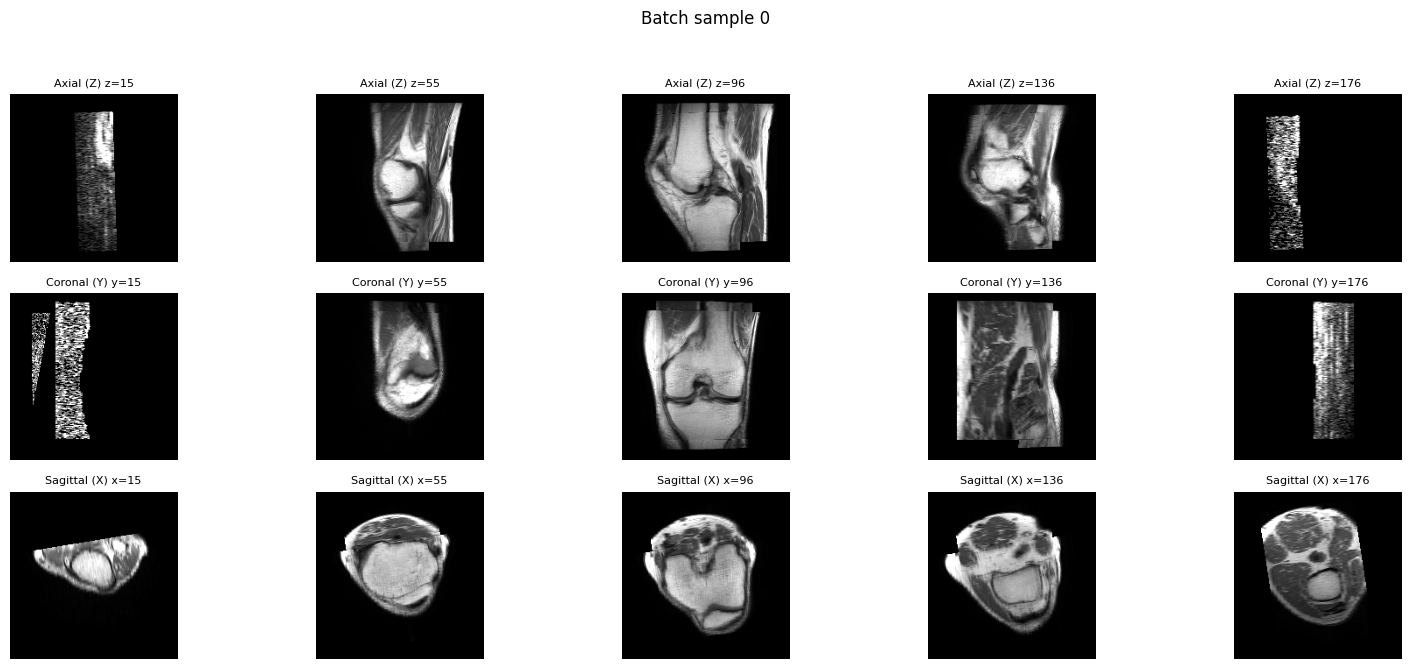

ImageSeriesReader (0x32a52f30): Non uniform sampling or missing slices detected,  maximum nonuniformity:0.000533456

ImageSeriesReader (0x32a52f30): Non uniform sampling or missing slices detected,  maximum nonuniformity:0.000590438



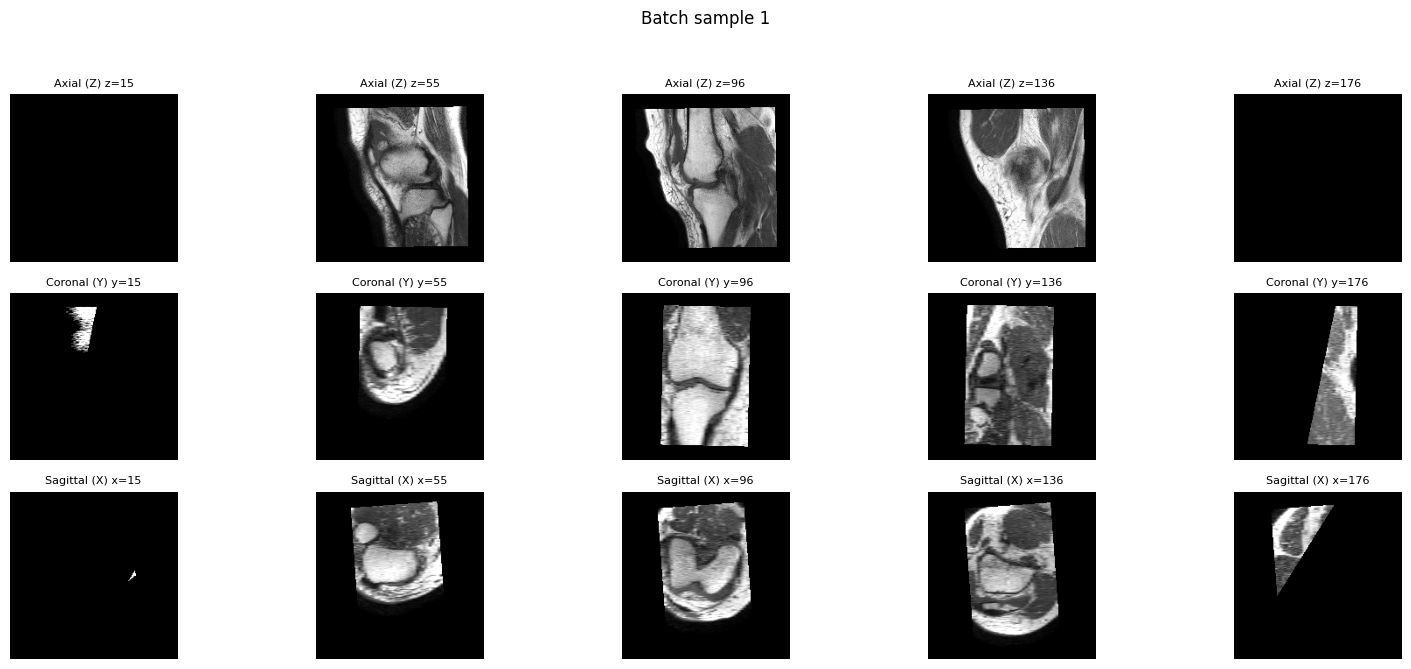

In [4]:
cfg = CONFIG
dm = KneeDataModule(cfg)
dm.setup()
tdl = dm.train_dataloader()

import matplotlib.pyplot as plt
import numpy as np

# %matplotlib inline

batch = next(iter(tdl))
images = batch["image_normal"]

# Приводим к обычному CPU tensor
images = images.detach().cpu().float()

# Если вдруг канал не добавился, подставим его
if images.ndim == 4:
    # (B, X, Y, Z) -> (B, 1, X, Y, Z)
    images = images.unsqueeze(1)
elif images.ndim == 3:
    # (X, Y, Z) -> (1, 1, X, Y, Z)
    images = images.unsqueeze(0).unsqueeze(0)

if images.ndim != 5:
    raise ValueError(f"Expected 5D image tensor, got {images.shape}")

B, C, S0, S1, S2 = images.shape

print("Batch image shape:", images.shape)
print(f"B={B}, C={C}, S0={S0}, S1={S1}, S2={S2}")

if "label" in batch:
    labels = batch["label"].detach().cpu().numpy()
    print("Labels shape:", labels.shape)
    print("Labels sample 0:", labels[0])


def visualize_volume(volume, title="Volume"):
    """
    volume: (C, S0, S1, S2)
    Для MONAI обычно это:
    C - каналы
    S0 - X
    S1 - Y
    S2 - Z
    """
    # Покажем первый канал. Для baseline C=1, так что это нормально.
    vol = volume[0].numpy()
    vol = np.nan_to_num(vol)

    n_slices = 5
    fracs = np.linspace(0.08, 0.92, n_slices)

    # Плоскости:
    # Axial:      фиксированный Z -> vol[:, :, z]
    # Coronal:    фиксированный Y -> vol[:, y, :]
    # Sagittal:   фиксированный X -> vol[x, :, :]
    planes = [
        ("Axial (Z)", S2, "z"),
        ("Coronal (Y)", S1, "y"),
        ("Sagittal (X)", S0, "x"),
    ]

    fig, axes = plt.subplots(
        3,
        n_slices,
        figsize=(3.2 * n_slices, 7),
        squeeze=False,
    )

    for r, (name, size, axis) in enumerate(planes):
        for c, frac in enumerate(fracs):
            idx = int(round(frac * (size - 1)))

            if axis == "z":
                sl = vol[:, :, idx]
            elif axis == "y":
                sl = vol[:, idx, :]
            else:  # x
                sl = vol[idx, :, :]

            # Небольшой percentile clipping, чтобы выбросы не “съели” картинку
            p1, p99 = np.percentile(sl, (1, 99))
            if p99 <= p1:
                p1, p99 = 0, 1

            axes[r, c].imshow(
                sl,
                cmap="gray",
                vmin=p1,
                vmax=p99,
                origin="lower",
            )
            axes[r, c].set_title(f"{name} {axis}={idx}", fontsize=8)
            axes[r, c].axis("off")

    fig.suptitle(title)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])

    # Раскомментируй, если хочешь сохранить картинку:
    # plt.savefig("viz_batch.png", dpi=150, bbox_inches="tight")

    plt.show()


# Показываем до 2 образцов из батча
for b in range(min(2, B)):
    visualize_volume(images[b], title=f"Batch sample {b}")


In [7]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import pytorch_lightning as pl
import numpy as np
from typing import List, Optional

# Предполагаем, что эти импорты уже есть в вашем файле
# from monai.networks.nets import resnet50 
# или откуда вы берете resnet50

class CrossAttentionPooling(nn.Module):
    def __init__(self, d_model: int = 2048, n_queries: int = 16, num_heads: int = 8):
        super().__init__()
        assert d_model % num_heads == 0, "d_model must be divisible by num_heads"
        
        self.d_model = d_model
        self.n_queries = n_queries
        self.num_heads = num_heads
        self.head_dim = d_model // num_heads

        # Learnable queries
        self.query_tokens = nn.Parameter(torch.randn(1, n_queries, d_model) * 0.02)
        
        self.proj_k = nn.Linear(d_model, d_model)
        self.proj_v = nn.Linear(d_model, d_model)
        self.proj_out = nn.Linear(d_model, d_model)
        
        self.norm_q = nn.LayerNorm(d_model)
        self.norm_kv = nn.LayerNorm(d_model)
        self.norm_out = nn.LayerNorm(d_model)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: [B, C, D, H, W]
        Returns:
            [B, n_queries * d_model]
        """
        B, C, D, H, W = x.shape
        
        # Преобразуем в последовательность токенов: [B, L, C], где L = D*H*W
        tokens = x.flatten(2).transpose(1, 2) 

        # Нормализация и проекция K, V
        tokens_norm = self.norm_kv(tokens)
        k = self.proj_k(tokens_norm)
        v = self.proj_v(tokens_norm)

        # Подготовка Q
        q = self.query_tokens.expand(B, -1, -1)
        q = self.norm_q(q)

        # Reshape для Multi-Head Attention
        # [B, Heads, Queries, HeadDim] и [B, Heads, L, HeadDim]
        q = q.view(B, self.n_queries, self.num_heads, self.head_dim).transpose(1, 2)
        k = k.view(B, -1, self.num_heads, self.head_dim).transpose(1, 2)
        v = v.view(B, -1, self.num_heads, self.head_dim).transpose(1, 2)

        # Внимание
        out = F.scaled_dot_product_attention(q, k, v)

        # Обратное преобразование
        out = out.transpose(1, 2).reshape(B, self.n_queries, self.d_model)
        
        out = self.norm_out(out)
        out = self.proj_out(out)
        
        # Возвращаем сплющенный вектор для классификатора
        return out.flatten(1)


class ResNet3DMultilabel(pl.LightningModule):
    def __init__(
        self,
        cfg: dict,
        label_names: List[str],
        pos_weight: Optional[torch.Tensor] = None,
        n_queries: int = 16,
        num_heads: int = 8,
    ):
        super().__init__()
        self.cfg = cfg
        self.label_names = list(label_names)
        self.num_classes = len(self.label_names)

        # self.backbone = resnet50(
        #     pretrained=True, 
        #     n_input_channels=1, 
        #     feed_forward=False, # Это важно! Отключает финальный FC слой
        #     shortcut_type='B',  
        #     bias_downsample=False
        # )


        # self.backbone = resnet18(
        #     pretrained=True, 
        #     n_input_channels=1, 
        #     feed_forward=False, # Это важно! Отключает финальный FC слой
        #     shortcut_type='A',  
        #     bias_downsample=True
        # )

        # self.backbone.avgpool = nn.Identity()


        model = torch.hub.load("facebookresearch/pytorchvideo", "i3d_r50", pretrained=True)

        model.blocks[0].conv = torch.nn.Conv3d(1, 64, kernel_size=(5, 7, 7), stride=(1, 2, 2), padding=(2, 3, 3), bias=False)
        model.blocks[6] = torch.nn.Identity()

        self.backbone = model

        self.feature_dim = 2048
            
        print("Feature dim: ", self.feature_dim)
        
        self.cap = CrossAttentionPooling(
            d_model=self.feature_dim,
            n_queries=n_queries,
            num_heads=num_heads
        )
        
        self.norm_before_classifier = nn.LayerNorm(n_queries * self.feature_dim)
        self.classifier = nn.Linear(n_queries * self.feature_dim, self.num_classes)

        if pos_weight is not None:
            if not isinstance(pos_weight, torch.Tensor):
                pos_weight = torch.as_tensor(pos_weight, dtype=torch.float32)
            self.register_buffer("pos_weight", pos_weight, persistent=False)
        else:
            self.pos_weight = None

        self.val_preds: List[torch.Tensor] = []
        self.val_labels: List[torch.Tensor] = []

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: [B, 1, D, H, W]
        """
        B, C, D, H, W = x.shape
        #x = x.permute(0, 2, 1, 3, 4)
        features = self.backbone(x)
        print(features.shape)
        features = features.reshape((B, self.feature_dim, D//2, H//32, W//32))
            
        # Применяем Cross Attention Pooling
        # На входе [B, C, D, H, W], на выходе [B, n_queries * C]
        pooled = self.cap(features)
        
        # Нормализация и классификация
        pooled = self.norm_before_classifier(pooled)
        logits = self.classifier(pooled)
        
        return logits

    def _loss(self, logits: torch.Tensor, labels: torch.Tensor) -> torch.Tensor:
        return nn.BCEWithLogitsLoss()(logits, labels, ) #pos_weight=self.pos_weight
        #return nn.CrossEntropyLoss()(logits, labels)

    def training_step(self, batch: Dict[str, torch.Tensor], batch_idx: int) -> torch.Tensor:
        images = batch["image_normal"]
        labels = batch["label"]

        logits = self(images)
        loss = self._loss(logits, labels)

        self.log(
            "train_loss",
            loss,
            prog_bar=True,
            on_step=True,
            on_epoch=True,
            batch_size=images.size(0),
            sync_dist=True,
        )

        return loss

    def validation_step(self, batch: Dict[str, torch.Tensor], batch_idx: int) -> None:
        images = batch["image_normal"]
        labels = batch["label"]

        logits = self(images)
        loss = self._loss(logits, labels)

        self.log(
            "val_loss",
            loss,
            prog_bar=True,
            on_step=True,
            on_epoch=True,
            batch_size=images.size(0),
            sync_dist=True,
        )

        probs = torch.sigmoid(logits)
        self.val_preds.append(probs.detach().cpu())
        self.val_labels.append(labels.detach().cpu())

        return loss

    def _safe_binary_auc(
        self,
        y_true: np.ndarray,
        y_score: np.ndarray,
        threshold: float = 0.5,
        allow_soft_labels: bool = True,
    ) -> Optional[float]:
        """
        Safe binary AUC для одного label.

        Поддерживает:
        - y_true как int 0/1
        - y_true как float 0.0/1.0
        - y_true как soft labels в [0, 1], если allow_soft_labels=True
        - NaN/inf

        Для soft labels делаем бинаризацию:
        y_true > threshold -> 1
        y_true <= threshold -> 0
        """
        mask = np.isfinite(y_true) & np.isfinite(y_score)
        if int(mask.sum()) < 2:
            return None

        yt = y_true[mask]
        yp = y_score[mask]

        # Оставляем только те y_true, которые выглядят как labels в [0, 1]
        valid = (yt >= 0.0) & (yt <= 1.0)
        yt = yt[valid]
        yp = yp[valid]

        if len(yt) < 2:
            return None

        yt_round = np.round(yt, 6)
        unique_vals = np.unique(yt_round)

        # Если лейблы фактически бинарные: 0 / 1
        if np.all(np.isin(unique_vals, [0.0, 1.0])):
            yt_bin = yt_round.astype(int)
        else:
            # Если лейблы soft, например 0.2, 0.7, 0.9
            if not allow_soft_labels:
                return None

            yt_bin = (yt > threshold).astype(int)

        # Для AUC нужны оба класса
        if len(np.unique(yt_bin)) < 2:
            return None

        # Если предсказания константные, AUC неинформативный
        if np.all(yp == yp[0]):
            return None

        try:
            return float(roc_auc_score(yt_bin, yp))
        except Exception:
            return None

    def _macro_auc(
        self,
        y_true: np.ndarray,
        y_pred: np.ndarray,
        default_auc: Optional[float] = 0.5,
    ) -> float:
        """
        Macro AUC по 12 label'ам.

        Если по какому-то label AUC нельзя посчитать локально,
        используем default_auc. Для маленького val это обычно 0.5.

        Если не хочешь default_auc, можно передать default_auc=None,
        но тогда при пустом списке будет ошибка.
        """
        aucs = []

        for i in range(y_true.shape[1]):
            auc = self._safe_binary_auc(
                y_true[:, i],
                y_pred[:, i],
            )

            if auc is None:
                if default_auc is None:
                    continue
                auc = default_auc

            aucs.append(auc)

        if len(aucs) == 0:
            if default_auc is None:
                raise RuntimeError(
                    "Cannot compute macro AUC: no valid label has enough binary samples."
                )
            return float(default_auc)

        return float(np.mean(aucs))

    def on_validation_epoch_end(self) -> None:
        if len(self.val_preds) == 0:
            return

        y_pred = torch.cat(self.val_preds, dim=0).numpy()
        y_true = torch.cat(self.val_labels, dim=0).numpy()

        auc = self._macro_auc(y_true, y_pred, default_auc=0.5)
        self.log("val_auc", auc, prog_bar=True, on_epoch=True, sync_dist=True)

        for i, name in enumerate(self.label_names):
            auc_i = self._safe_binary_auc(
                y_true[:, i],
                y_pred[:, i],
            )

            if auc_i is None:
                continue

            safe_name = name.replace(" ", "_").replace("'", "_")
            self.log(
                f"val_auc_{safe_name}",
                float(auc_i),
                on_epoch=True,
            )

        self.val_preds.clear()
        self.val_labels.clear()

    def configure_optimizers(self):
        cfg = self.cfg
        optimizer = torch.optim.AdamW(
            self.parameters(),
            lr=float(cfg.get("learning_rate", 1e-4)),
            weight_decay=float(cfg.get("weight_decay", 1e-2)),
        )

        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer,
            T_max=max(1, int(cfg.get("epochs", 10))),
            eta_min=1e-6,
        )

        return [optimizer], [scheduler]

In [8]:
model = ResNet3DMultilabel(CONFIG, LABEL_COLUMNS)
out = model(torch.randn((1, 1, 192, 192, 192)))
out.shape

Using cache found in /home/maxim/.cache/torch/hub/facebookresearch_pytorchvideo_main


Feature dim:  2048
torch.Size([1, 2048, 96, 6, 6])


torch.Size([1, 12])

In [9]:
from sklearn.metrics import roc_auc_score


def compute_pos_weight(
    train_df: pd.DataFrame,
    label_names: List[str],
    max_weight: float = 8.0,
) -> Optional[torch.Tensor]:
    # ВАЖНО: train_df[label_names] — DataFrame,
    # поэтому применяем pd.to_numeric по колонкам.
    labels = train_df[label_names].apply(
        lambda col: pd.to_numeric(col, errors="coerce")
    )

    # Оставляем только строки, где все 12 label'ов присутствуют.
    mask = ~labels.isna().any(axis=1)
    labels = labels[mask].to_numpy(dtype=np.float32)

    if len(labels) == 0:
        return None

    pos = labels.sum(axis=0)
    neg = len(labels) - pos
    pos = np.clip(pos, 1.0, None)

    weights = neg / pos
    weights = np.clip(weights, 1.0, float(max_weight))

    return torch.tensor(weights, dtype=torch.float32)


def create_logger(cfg: dict):
    mlflow_cfg = cfg.get("mlflow", {})

    try:
        logger = MLFlowLogger(
            tracking_uri=mlflow_cfg.get("tracking_uri", "./mlruns"),
            experiment_name=mlflow_cfg.get("experiment_name", "knee_mri_multilabel"),
            run_name=mlflow_cfg.get("run_name", "knee_baseline"),
        )
        return logger
    except Exception as e:
        print(f"MLFlowLogger failed: {e}. Falling back to CSVLogger.")

    return CSVLogger(save_dir=os.path.join(WORKING_DIR, "lightning_logs"))


def train_model(
    cfg: Optional[dict] = None,
    limit_train_batches: Optional[float] = None,
    limit_val_batches: Optional[float] = None,
    max_epochs: Optional[int] = None,
):
    if cfg is None:
        cfg = CONFIG

    cfg = copy.deepcopy(cfg)
    pl.seed_everything(int(cfg.get("seed", 42)), workers=True)

    label_names = cfg["label_columns"]

    # train_path = os.path.join(cfg["data_root"], cfg["train_csv"])
    # train_df = pd.read_csv(
    #     train_path,
    #     usecols=["StudyInstanceUID"] + label_names,
    #     dtype={"StudyInstanceUID": str},
    # )
    # train_df["StudyInstanceUID"] = train_df["StudyInstanceUID"].astype(str)

    # mcfg = cfg.get("model", {})
    # pos_weight = None

    # if mcfg.get("use_pos_weight", False):
    #     pos_weight = compute_pos_weight(
    #         train_df,
    #         label_names,
    #         max_weight=float(mcfg.get("max_pos_weight", 8.0)),
    #     )

    #     if pos_weight is None:
    #         pos_weight = torch.ones(len(label_names), dtype=torch.float32)

    dm = KneeDataModule(cfg)
    model = ResNet3DMultilabel(
        cfg=cfg,
        label_names=label_names,
        #pos_weight=pos_weight,
    )

    logger = create_logger(cfg)

    hyper = {
        k: str(v)
        for k, v in cfg.items()
        if isinstance(v, (str, int, float, bool))
    }

    try:
        logger.log_hyperparams(hyper)
    except Exception as e:
        print(f"Failed to log hyperparams: {e}")

    checkpoint_dir = os.path.join(WORKING_DIR, "checkpoints")

    callbacks = [
        LearningRateMonitor(logging_interval="epoch"),
        ModelCheckpoint(
            dirpath=checkpoint_dir,
            filename="best_{epoch}-{val_auc:.4f}",
            monitor="val_auc",
            mode="max",
            save_top_k=1,
            save_last=True,
        ),
        EarlyStopping(
            monitor="val_auc",
            mode="max",
            patience=30,
            verbose=True,
        ),
    ]

    accelerator = "gpu" if torch.cuda.is_available() else "cpu"
    precision = str(cfg.get("precision", "32"))

    if accelerator == "cpu":
        precision = "32"

    devices = int(cfg.get("gpus", 1)) if accelerator == "gpu" else 1

    if limit_train_batches is None:
        limit_train_batches = float(cfg.get("limit_train_batches", 1.0))

    if limit_val_batches is None:
        limit_val_batches = float(cfg.get("limit_val_batches", 1.0))

    trainer = pl.Trainer(
        max_epochs=int(max_epochs if max_epochs is not None else cfg.get("epochs", 10)),
        accelerator=accelerator,
        devices=devices,
        precision=precision,
        logger=[logger],
        callbacks=callbacks,
        val_check_interval=1.0,
        num_sanity_val_steps=2,
        limit_train_batches=limit_train_batches,
        limit_val_batches=limit_val_batches,
        accumulate_grad_batches=cfg["accumulate_grad_batches"],
        gradient_clip_val=1.0,
        enable_progress_bar=True,
    )

    trainer.fit(model, datamodule=dm)

    best_path = None
    if trainer.checkpoint_callback is not None:
        best_path = trainer.checkpoint_callback.best_model_path

    last_path = os.path.join(checkpoint_dir, "last.ckpt")
    if not os.path.exists(last_path):
        last_path = None

    print("Best checkpoint:", best_path)
    print("Last checkpoint:", last_path)

    return {
        "best": best_path,
        "last": last_path,
        "trainer": trainer,
    }


In [10]:
# Запуск обучения.
# Для smoke test: в Cell 2 поставь SMOKE_TEST = True
TRAIN_RESULT = train_model()

BEST_CHECKPOINT = TRAIN_RESULT.get("best") or TRAIN_RESULT.get("last")
print("Checkpoint to use:", BEST_CHECKPOINT)


Seed set to 42
Using cache found in /home/maxim/.cache/torch/hub/facebookresearch_pytorchvideo_main
The filesystem tracking backend (e.g., './mlruns') is deprecated as of February 2026. Consider transitioning to a database backend (e.g., 'sqlite:///mlflow.db') to take advantage of the latest MLflow features. See https://mlflow.org/docs/latest/self-hosting/migrate-from-file-store for migration guidance.
Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
`Trainer(limit_train_batches=1.0)` was configured so 100% of the batches per epoch will be used..
`Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
`Trainer(val_check_interval=1.0)` was configured so vali

Feature dim:  2048
Val studies: 58, Train studies: 4349
Preparing train studies data...


Checkpoint directory /home/maxim/Desktop/RSNA KAD/checkpoints exists and is not empty.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Preparing val studies data...
Train studies with data: 4349
Val studies with data: 58
Train dataset len: 4349
Val dataset len: 58


Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.


┏━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name                   ┃ Type                  ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ backbone               │ Net                   │ 27.2 M │ train │     0 │
│ 1 │ cap                    │ CrossAttentionPooling │ 12.6 M │ train │     0 │
│ 2 │ norm_before_classifier │ LayerNorm             │ 65.5 K │ train │     0 │
│ 3 │ classifier             │ Linear                │  393 K │ train │     0 │
└───┴────────────────────────┴───────────────────────┴────────┴───────┴───────┘

... (2,818 outputs left out)

torch.Size([4, 2048, 96, 6, 6])

ImageSeriesReader (0x33b9a1b0): Non uniform sampling or missing slices detected,  maximum nonuniformity:0.000587028

ImageSeriesReader (0xf0d7f870): Non uniform sampling or missing slices detected,  maximum nonuniformity:0.000794035


Detected KeyboardInterrupt, attempting graceful shutdown ...


SystemExit: 1

To exit: use 'exit', 'quit', or Ctrl-D.
